# 09 · Od perceptronu k vyladěnému klasifikátoru

Praktická část cvičení 09. Na datech z kontroly výlisků naučíte perceptron a logistický neuron,
vyhodnotíte je metrikami z přednášky, **samostatně je vyladíte**, zvolíte rozhodovací práh podle ceny chyb
a výsledek jednou otestujete. Každé nastavení, které zde ladíte, jste viděli jako graf v edukační části `perceptron-visual-cz.ipynb`.

Krátké spustitelné ukázky používají malá ilustrační data a proměnné s předponou `demo_`. Spouštějte je v pořadí:
na sebe navazují a ukazují syntaxi celého postupu. Vlastní řešení pište do prázdných kódových buněk pod úkoly.
Testovací data se otevřou až v kroku 7. Po dokončení spusťte `Restart Kernel and Run All` a ověřte, že řešení běží v pořadí.

## Příprava prostředí a načtení dat

1. Otevřete notebook v Jupyteru (balíčky popisuje README) nebo v Google Colab.
2. Spusťte ukázku níže. Importuje všechny potřebné nástroje a připraví malá ilustrační data `demo_`.
3. Připravená buňka pod ní načte data do tabulky `raw` a nastaví `SEED = 42` pro všechny náhodné kroky. Když notebook běží ve složce
   cvičení nebo v kořeni repozitáře, použije místní soubor `data/parts.csv`; jinak stejný soubor stáhne z GitHubu
   (je potřeba připojení k internetu).

### Ukázka: importy a ilustrační data

In [1]:
import warnings                                              # Potlačení varování o nedokončeném učení (viz níže).
from IPython.display import display                          # Zobrazení tabulek ve vlastních úkolech.
import matplotlib.pyplot as plt                              # Grafy.
import numpy as np                                           # Numerické výpočty.
import pandas as pd                                          # Data a tabulky výsledků.
from sklearn.base import clone                               # Nová nenaučená kopie nastavení modelu.
from sklearn.model_selection import train_test_split         # Rozdělení vstupů a cílů najednou.
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict  # Mřížkové hledání a křížová validace.
from sklearn.pipeline import Pipeline                        # Řetězení kroků do jednoho modelu.
from sklearn.preprocessing import StandardScaler, PolynomialFeatures  # Standardizace a nové součinové příznaky.
from sklearn.linear_model import Perceptron, SGDClassifier  # Perceptron a neuron učený stochastickým gradientním sestupem.
from sklearn.dummy import DummyClassifier                    # Jednoduchý referenční model.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay  # Matice záměn jako čísla a jako graf.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score  # Metriky tvrdých rozhodnutí.
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay  # Metriky a křivky přes všechny prahy.
from sklearn.exceptions import ConvergenceWarning            # Typ varování pro učení zastavené limitem epoch.

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # Malé rychlosti a málo epoch ladíme záměrně; posuzujeme výsledek, ne varování.

demo_rng = np.random.default_rng(7)                          # Ilustrační data, ne data úlohy.
demo_X = pd.DataFrame({"size": demo_rng.normal(50, 10, 300),       # Příznak v desítkách.
                       "weight": demo_rng.normal(2000, 300, 300)})  # Příznak v tisících.
demo_risk = -2.2 + 0.09 * (demo_X["size"] - 50) + 0.004 * (demo_X["weight"] - 2000)  # Skryté riziko třídy 1.
demo_y = (demo_rng.random(300) < 1 / (1 + np.exp(-demo_risk))).astype(int)  # Asi 15 % třídy 1.
demo_X_dev, demo_X_test, demo_y_dev, demo_y_test = train_test_split(demo_X, demo_y, test_size=0.25, stratify=demo_y, random_state=7)  # Čtvrtina pro test.
demo_X_train, demo_X_val, demo_y_train, demo_y_val = train_test_split(demo_X_dev, demo_y_dev, test_size=0.25, stratify=demo_y_dev, random_state=7)  # Čtvrtina zbytku pro validaci.
print(len(demo_X_train), len(demo_X_val), len(demo_X_test), "podíl třídy 1:", round(demo_y.mean(), 3))  # Velikosti tří částí.

168 57 75 podíl třídy 1: 0.147


**Připravený kód:**

In [2]:
from pathlib import Path                                     # Cesty k místní kopii dat.
SEED = 42                                                    # Stejné náhodné dělení a učení pro všechny.
DATA_URL = ("https://raw.githubusercontent.com/CVUT-FS-12110/Artificial-Intelligence-and-Neural-Networks/"
            "master/09-Perceptron/data/parts.csv")           # Tentýž soubor v repozitáři předmětu na GitHubu.
local = [Path("data/parts.csv"), Path("09-Perceptron/data/parts.csv")]  # Složka cvičení nebo kořen repozitáře.
found = [path for path in local if path.exists()]           # Místní kopie, které existují.
source = found[0] if found else DATA_URL                     # Bez místní kopie (např. Google Colab) stáhnout z GitHubu.
raw = pd.read_csv(source)                                    # 2000 zkontrolovaných výlisků.
print("data načtena z:", source)          # Místní soubor nebo adresa URL.
display(raw.head())  # Prvních pět řádků.

data načtena z: data\parts.csv


,part_id,melt_temp,pressure,cooling_time,mould_temp,humidity,vibration,shot_weight,cycle_time,shrinkage,defect
0,P0001,214.6,870.0,12.09,62.4,43.3,0.516,52.27,29.40,1.383,0
1,P0002,229.2,853.0,13.38,51.4,40.3,0.377,51.77,29.90,1.463,0
2,P0003,230.0,834.0,10.49,63.2,28.5,0.336,52.67,29.29,1.586,0
3,P0004,233.3,954.0,14.11,52.2,35.9,0.248,52.89,29.79,1.466,0
4,P0005,236.4,934.0,13.29,59.6,31.0,1.629,51.92,30.68,1.636,1


## Úloha a data

Každý řádek je jeden **vstřikovaný výlisek** s osmi nastaveními procesu změřenými při jeho výrobě a výsledkem
výstupní kontroly `defect` (1 = vadný). Data jsou syntetická; jejich popis je v `data/README.md`.

| Sloupec | Význam | Typická hodnota |
|---|---|---|
| `melt_temp` | teplota taveniny | 230 °C |
| `pressure` | vstřikovací tlak | 900 bar |
| `cooling_time` | doba chlazení | 12 s |
| `mould_temp` | teplota formy | 60 °C |
| `humidity` | vlhkost ve skladu granulátu | 45 % |
| `vibration` | vibrace lisu | 0,5 mm/s |
| `shot_weight` | hmotnost dávky | 52 g |
| `cycle_time` | doba cyklu | 30 s |
| `shrinkage` | naměřené smrštění – v tomto cvičení se nepoužívá, **není vstupem** | 1,5 % |

**Cíl:** předpovědět výsledek kontroly z nastavení, aby se podezřelé výlisky poslaly na podrobnou kontrolu.
**Ceny:** vadný výlisek odeslaný zákazníkovi (FN) stojí **10** jednotek (reklamace), dobrý výlisek poslaný na podrobnou kontrolu
(FP) stojí **1** jednotku. Kvalita rozhodnutí se proto měří **celkovou cenou** C = 10·FN + 1·FP,
ne samotnou správností.

## 1. Prohlídka dat (připraveno)

**Výstup:** podíl vadných výlisků a tabulka rozsahů příznaků. Všimněte si, jak vzácná je třída 1 a jak rozdílná jsou měřítka.

**Připravený kód:**

In [3]:
print("řádků:", len(raw), "| chybějících hodnot:", int(raw.isna().sum().sum()))  # Velikost a úplnost.
print("podíl vadných výlisků:", round(raw["defect"].mean(), 3))  # Podíl třídy 1.
display(raw.drop(columns=["part_id", "defect"]).describe().T[["mean", "std", "min", "max"]].round(3))  # Rozsahy vstupů.

řádků: 2000 | chybějících hodnot: 0
podíl vadných výlisků: 0.107


,mean,std,min,max
melt_temp,229.992,6.041,210.200,248.800
pressure,898.732,59.870,674.000,1096.000
cooling_time,12.022,1.519,6.150,17.050
mould_temp,60.028,3.931,46.900,71.200
humidity,45.084,9.919,9.800,80.900
vibration,0.534,0.214,0.100,1.629
shot_weight,51.993,0.399,50.400,53.370
cycle_time,30.050,1.017,26.680,33.420
shrinkage,1.502,0.123,1.112,1.973


## 2. Příznaky a pevné rozdělení (připraveno)

**Výstup:** `X` (osm vstupů) a `y` (`defect`); vývojová část `X_dev`, `y_dev` (1500 výlisků) a testovací část `X_test`, `y_test`
(500 výlisků), která zůstává zavřená až do kroku 7. Vývojová část se dál dělí na trénovací `X_train`, `y_train` (1125)
a validační `X_val`, `y_val` (375). Všechna dělení jsou stratifikovaná: každá část zachovává podíl vadných.

**Připravený kód:**

In [4]:
FEATURES = ["melt_temp", "pressure", "cooling_time", "mould_temp", "humidity", "vibration", "shot_weight", "cycle_time"]  # Osm vstupů.
X = raw[FEATURES]                                            # Osm vstupů; part_id a shrinkage nejsou vstupy.
y = raw["defect"]                                            # Cílová třída.
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)  # Čtvrtina pro test, stratifikovaně.
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)  # Čtvrtina zbytku pro validaci.
for name, part in (("train", y_train), ("validation", y_val), ("dev", y_dev), ("test", y_test)):  # Výlisky a vady v každé části.
    print(f"{name:10s} {len(part):5d} výlisků, {int(part.sum()):4d} vadných")  # Jeden řádek na část.

train       1125 výlisků,  121 vadných
validation   375 výlisků,   40 vadných
dev         1500 výlisků,  161 vadných
test         500 výlisků,   53 vadných


## 3. Referenční model a funkce pro vyhodnocení (připraveno)

**Výstup:** funkce `evaluate(y_true, y_pred)`, která vrací počty z matice záměn, pět metrik a celkovou cenu,
a tabulka `reference` pro model, který vždy předpoví nejčastější třídu („každý výlisek je dobrý“).
Funkci `evaluate` použijte ve všech dalších krocích, aby byly výsledky srovnatelné.

**Připravený kód:**

In [5]:
C_FN, C_FP = 10, 1                                           # Cena přehlédnuté vady a planého poplachu.


def evaluate(y_true, y_pred):  # Používá se ve všech dalších krocích.
    # Počty z matice záměn, metriky a celková cena tvrdých rozhodnutí 0/1.
    y_pred = np.asarray(y_pred).astype(int)                  # Přijme i True/False.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()  # Čtyři počty v tomto pořadí.
    return {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),  # Počty z matice záměn.
            "správnost": accuracy_score(y_true, y_pred),  # (TP + TN) / n
            "přesnost": precision_score(y_true, y_pred, zero_division=0),  # 0, když není žádný poplach
            "úplnost": recall_score(y_true, y_pred),  # TP / (TP + FN)
            "F1": f1_score(y_true, y_pred, zero_division=0),  # harmonický průměr přesnosti a úplnosti
            "vyvážená správnost": balanced_accuracy_score(y_true, y_pred),  # (úplnost + specificita) / 2
            "cena": int(C_FN * fn + C_FP * fp)}  # C = 10·FN + 1·FP


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)  # Vždy předpoví „dobrý“.
reference = pd.DataFrame([evaluate(y_val, baseline.predict(X_val))], index=["vždy dobrý"])  # Validační výsledek reference.
display(reference.round(3))  # Zaokrouhlená tabulka.

,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
vždy dobrý,335,0,40,0,0.893,0.0,0.0,0.0,0.5,400


**Zamyslete se:** Referenční model má správnost asi 0,89. Proč je přesto k ničemu? Které metriky a jaká cena to ukazují?

## 4. Perceptron

**Cíl / výstup:** naučený `perceptron_pipe`, jeho validační předpovědi `val_pred_perceptron`, matice záměn, tabulka
`perceptron_results` srovnávající perceptron se škálováním a bez něj a seznam `epoch_errors` s trénovacími chybami po každé ze 30 epoch.

1. `perceptron_pipe` = `Pipeline` s kroky `scale`: `StandardScaler()` → `model`: `Perceptron(random_state=SEED)`.
   Naučte ho na trénovacích datech a předpovězte validační data.
2. Nakreslete matici záměn validačních předpovědí. Ze čtyř počtů spočtěte **ručně** přesnost a úplnost
   a porovnejte je s `evaluate`.
3. Naučte stejný perceptron **bez** škálování (jen `Perceptron(random_state=SEED)`). Oba výsledky `evaluate`
   vložte do `perceptron_results` spolu s `reference`.
4. Trénovací chyby po epochách: naučte `StandardScaler` na `X_train`, vytvořte nový `Perceptron(random_state=SEED)` a zavolejte
   30krát `partial_fit` na škálovaných trénovacích datech (jedno volání = jedna epocha). Po každé epoše uložte počet trénovacích chyb
   do `epoch_errors` a seznam vykreslete.

**Použijte:** `Pipeline`, `StandardScaler`, `Perceptron`, `.fit`, `.predict`, `ConfusionMatrixDisplay.from_predictions`,
`confusion_matrix(...).ravel()`, `evaluate`, `pd.DataFrame`, `.partial_fit(X, y, classes=[0, 1])`, `plt.plot`.

<details><summary>Nápověda</summary>

`tn, fp, fn, tp = confusion_matrix(y_val, val_pred).ravel()` dává čtyři počty v tomto pořadí. `Perceptron` se učí
pravidlem z přednášky (oprava po každém chybně zařazeném vzorku, v každé epoše v náhodném pořadí) a skončí, když trénovací chyba
přestane klesat. `partial_fit` udělá právě jeden průchod daty a pokračuje z aktuálních vah; první volání potřebuje
seznam všech tříd. Škálovač se učí jen na trénovacích datech a pak je transformuje:
`scaler.transform(X_train)`.

</details>

**Zamyslete se:** Ustálí se počet trénovacích chyb s přibývajícími epochami? Co to říká o datech
(edukační část, oddíl 3)? Která metrika se mezi perceptronem se škálováním a bez něj liší nejvíc?

### Ukázka: perceptron, matice záměn a chyby po epochách

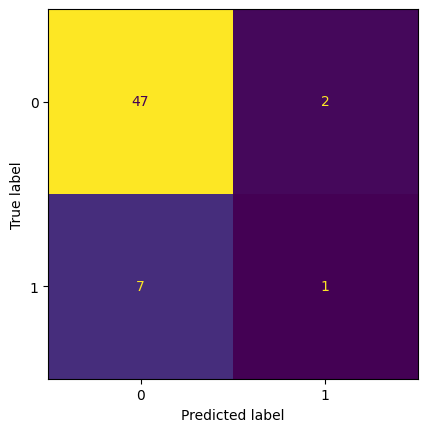

úplnost ručně: 0.125 | evaluate: 0.125
trénovací chyby po epochách: [29, 29, 25, 25, 27, 25, 25, 24, 22, 24]


In [6]:
demo_pipe = Pipeline([("scale", StandardScaler()), ("model", Perceptron(random_state=7))])  # Škálování, potom perceptron.
demo_pipe.fit(demo_X_train, demo_y_train)                    # Škálovač i váhy se učí jen z trénovacích dat.
demo_pred = demo_pipe.predict(demo_X_val)  # Validační předpovědi 0/1.
ConfusionMatrixDisplay.from_predictions(demo_y_val, demo_pred, colorbar=False)  # Řádky: skutečná třída, sloupce: předpověď.
plt.show()  # Zobrazit graf.
demo_tn, demo_fp, demo_fn, demo_tp = confusion_matrix(demo_y_val, demo_pred).ravel()  # Čtyři počty.
print("úplnost ručně:", demo_tp / (demo_tp + demo_fn), "| evaluate:", evaluate(demo_y_val, demo_pred)["úplnost"])  # Stejná hodnota oběma způsoby.

demo_scaler = StandardScaler().fit(demo_X_train)             # Samostatně naučený škálovač pro smyčku po epochách.
demo_Z = demo_scaler.transform(demo_X_train)  # Škálované trénovací vstupy.
demo_model, demo_errors = Perceptron(random_state=7), []  # Nový perceptron a prázdný seznam.
for demo_epoch in range(10):                                 # Deset epoch; jedno volání partial_fit = jeden průchod daty.
    demo_model.partial_fit(demo_Z, demo_y_train, classes=[0, 1])  # Jedna epocha.
    demo_errors.append(int((demo_model.predict(demo_Z) != demo_y_train).sum()))  # Trénovací chyby po epoše.
print("trénovací chyby po epochách:", demo_errors)  # Nemusí klesat.

**Vlastní kód:**

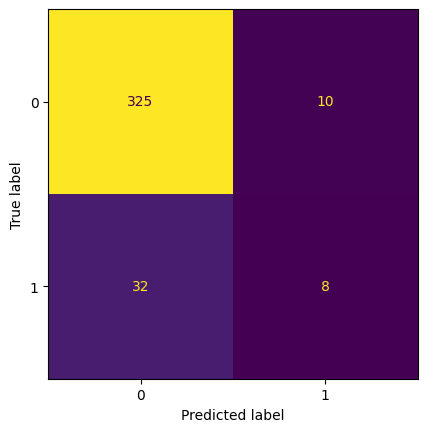

přesnost ručně 0.444 | evaluate 0.444
úplnost ručně 0.200 | evaluate 0.200


,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
vždy dobrý,335,0,40,0,0.893,0.000,0.0,0.000,0.500,400
perceptron se škálováním,325,10,32,8,0.888,0.444,0.2,0.276,0.585,330
perceptron bez škálování,335,0,40,0,0.893,0.000,0.0,0.000,0.500,400


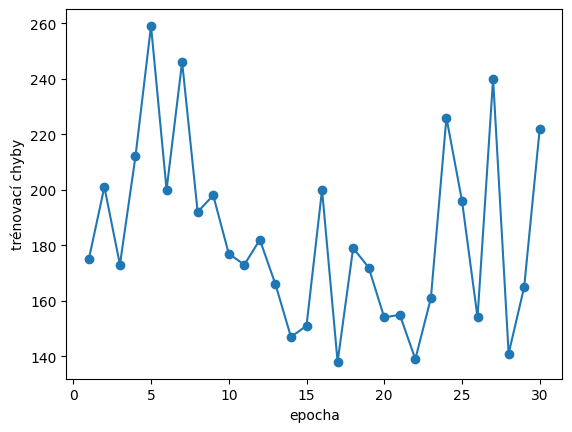

[175, 201, 173, 212, 259, 200, 246, 192, 198, 177, 173, 182, 166, 147, 151, 200, 138, 179, 172, 154, 155, 139, 161, 226, 196, 154, 240, 141, 165, 222]


In [7]:
perceptron_pipe = Pipeline([("scale", StandardScaler()), ("model", Perceptron(random_state=SEED))])
perceptron_pipe.fit(X_train, y_train)
val_pred_perceptron = perceptron_pipe.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, val_pred_perceptron, colorbar=False)
plt.show()  # Zobrazit graf.

tn, fp, fn, tp = confusion_matrix(y_val, val_pred_perceptron).ravel()
check = evaluate(y_val, val_pred_perceptron)
print(f"přesnost ručně {tp / (tp + fp):.3f} | evaluate {check['přesnost']:.3f}")
print(f"úplnost ručně {tp / (tp + fn):.3f} | evaluate {check['úplnost']:.3f}")

unscaled = Perceptron(random_state=SEED).fit(X_train, y_train)
perceptron_results = pd.concat([reference, pd.DataFrame(
    [check, evaluate(y_val, unscaled.predict(X_val))],
    index=["perceptron se škálováním", "perceptron bez škálování"])])
display(perceptron_results.round(3))

scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
model, epoch_errors = Perceptron(random_state=SEED), []
for epoch in range(30):
    model.partial_fit(Z_train, y_train, classes=[0, 1])
    epoch_errors.append(int((model.predict(Z_train) != y_train).sum()))
plt.plot(range(1, 31), epoch_errors, marker="o")
plt.xlabel("epocha")
plt.ylabel("trénovací chyby")
plt.show()  # Zobrazit graf.
print(epoch_errors)

**Poznámky k řešení (krok 4).** Perceptron se škálováním na validaci: TN 325, FP 10, FN 32, TP 8 – přesnost 0,44, úplnost 0,20, cena 330
(reference 400). Perceptron bez škálování předpovídá jen třídu 0, stejně jako reference: tlak ve stovkách ovládne každou opravu
(edukační část, oddíl 4). Trénovací chyby během 30 epoch skáčou zhruba mezi 140 a 260 z 1125 a nikdy se neustálí, protože se třídy překrývají
(oddíl 3); poslední váhy jsou libovolným bodem této oscilace. Perceptron se škálováním a bez něj se nejvíc liší v úplnosti, F1 a vyvážené správnosti.

## 5. Logistický neuron

**Cíl / výstup:** naučený `logistic_pipe`, validační pravděpodobnosti třídy 1 `val_proba`, tabulka `step5_results`
s perceptronem a logistickým neuronem při prahu 0,5, čísla `val_auc` a `val_ap` a tři grafy:
křivky ROC a křivky přesnost–úplnost obou modelů a histogram `val_proba` pro každou třídu.

1. `logistic_pipe` = `Pipeline`: `scale`: `StandardScaler()` → `model`:
   `SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, alpha=1e-4, random_state=SEED)`.
   Je to jeden logistický neuron učený stochastickým gradientním sestupem s konstantní rychlostí učení η = `eta0`
   a malou regularizací vah `alpha`.
2. Naučte ho na trénovacích datech, uložte `val_proba = logistic_pipe.predict_proba(X_val)[:, 1]` a tvrdé předpovědi při 0,5 (`.predict`).
   Výsledek `evaluate` přidejte do `step5_results` spolu s perceptronem se škálováním z kroku 4.
3. Z `val_proba` spočtěte `val_auc` (ROC AUC) a `val_ap` (plocha pod křivkou přesnost–úplnost). Pro perceptron použijte jeho skóre
   `perceptron_pipe.decision_function(X_val)`: ROC a PR potřebují jen pořadí, ne pravděpodobnost.
4. Nakreslete obě křivky ROC do jednoho grafu a obě křivky přesnost–úplnost do druhého. Nakreslete histogram `val_proba` zvlášť pro
   dobré a vadné výlisky.

**Použijte:** `SGDClassifier`, `.predict_proba`, `.decision_function`, `roc_auc_score`, `average_precision_score`,
`RocCurveDisplay.from_predictions`, `PrecisionRecallDisplay.from_predictions`, `plt.hist`.

<details><summary>Nápověda</summary>

Bez `learning_rate="constant"` používá klasifikátor vlastní rozvrh a **`eta0` ignoruje** – ladění v kroku 6 by pak
nic neměnilo. `predict_proba` vrací dva sloupce (třída 0 a třída 1); `[:, 1]` vybere třídu 1. Obě zobrazovací funkce přijímají
`ax=` pro kreslení do připravené osy: `fig, axs = plt.subplots(1, 2)`, potom `RocCurveDisplay.from_predictions(y_val, scores, name="...", ax=axs[0])`.
Histogram jedné třídy: `plt.hist(val_proba[y_val == 1], bins=20)`.

</details>

**Zamyslete se:** AUC je zřetelně nad 0,5, a přesto je při prahu 0,5 úplnost nízká. Kde v histogramu leží většina vadných výlisků?
Co by se stalo s úplností, přesností a cenou při prahu 0,1?

### Ukázka: pravděpodobnosti, AUC a křivky

AUC: 0.811 | AP: 0.476


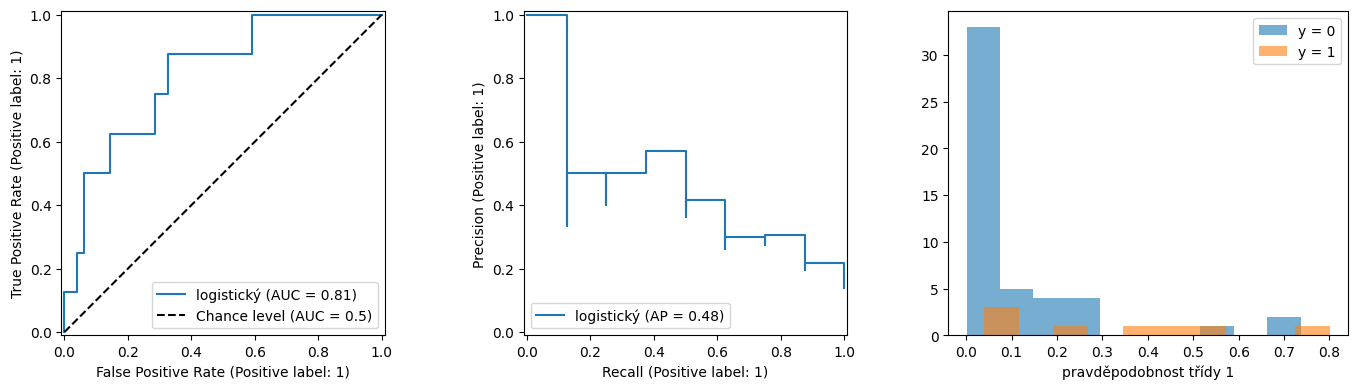

In [8]:
demo_logistic = Pipeline([("scale", StandardScaler()),  # Nejdřív škálování …
                          ("model", SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.05, random_state=7))])  # Jeden logistický neuron.
demo_logistic.fit(demo_X_train, demo_y_train)  # Učení na trénovacích datech.
demo_proba = demo_logistic.predict_proba(demo_X_val)[:, 1]  # Pravděpodobnost třídy 1.
print("AUC:", round(roc_auc_score(demo_y_val, demo_proba), 3), "| AP:", round(average_precision_score(demo_y_val, demo_proba), 3))  # Obě míry využívají celé pořadí.
fig, axs = plt.subplots(1, 3, figsize=(14, 4))  # Tři grafy vedle sebe.
RocCurveDisplay.from_predictions(demo_y_val, demo_proba, name="logistický", ax=axs[0], plot_chance_level=True)  # Křivka ROC s úhlopříčkou náhodného modelu.
PrecisionRecallDisplay.from_predictions(demo_y_val, demo_proba, name="logistický", ax=axs[1])  # Křivka přesnost–úplnost.
axs[2].hist(demo_proba[demo_y_val == 0], bins=10, alpha=0.6, label="y = 0")  # Pravděpodobnosti třídy 0 …
axs[2].hist(demo_proba[demo_y_val == 1], bins=10, alpha=0.6, label="y = 1")  # … a třídy 1.
axs[2].set(xlabel="pravděpodobnost třídy 1")  # Popis osy.
axs[2].legend()  # Legenda.
plt.tight_layout()  # Popisky se nepřekrývají.
plt.show()  # Zobrazit graf.

**Vlastní kód:**

,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
perceptron,325,10,32,8,0.888,0.444,0.200,0.276,0.585,330
"logistický neuron, práh 0,5",333,2,37,3,0.896,0.600,0.075,0.133,0.535,372


práh 0,1: {'TN': 227, 'FP': 108, 'FN': 11, 'TP': 29, 'správnost': 0.683, 'přesnost': 0.212, 'úplnost': 0.725, 'F1': 0.328, 'vyvážená správnost': 0.701, 'cena': 218}
logistický neuron: AUC 0.750, AP 0.353
perceptron: AUC 0.728, AP 0.341


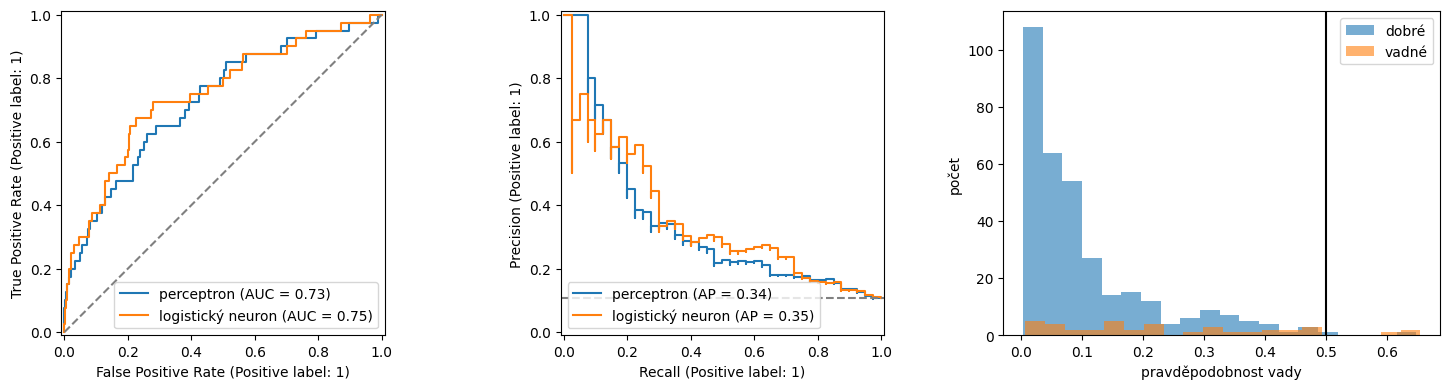

In [9]:
logistic_pipe = Pipeline([("scale", StandardScaler()),
                          ("model", SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, alpha=1e-4, random_state=SEED))])
logistic_pipe.fit(X_train, y_train)
val_proba = logistic_pipe.predict_proba(X_val)[:, 1]
step5_results = pd.DataFrame([evaluate(y_val, val_pred_perceptron), evaluate(y_val, logistic_pipe.predict(X_val))],
                             index=["perceptron", "logistický neuron, práh 0,5"])
display(step5_results.round(3))
print("práh 0,1:", {k: round(v, 3) for k, v in evaluate(y_val, val_proba >= 0.1).items()})

perceptron_scores = perceptron_pipe.decision_function(X_val)
val_auc, val_ap = roc_auc_score(y_val, val_proba), average_precision_score(y_val, val_proba)
print(f"logistický neuron: AUC {val_auc:.3f}, AP {val_ap:.3f}")
print(f"perceptron: AUC {roc_auc_score(y_val, perceptron_scores):.3f}, AP {average_precision_score(y_val, perceptron_scores):.3f}")

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for scores, name in ((perceptron_scores, "perceptron"), (val_proba, "logistický neuron")):
    RocCurveDisplay.from_predictions(y_val, scores, name=name, ax=axs[0])
    PrecisionRecallDisplay.from_predictions(y_val, scores, name=name, ax=axs[1])
axs[0].plot([0, 1], [0, 1], color="grey", ls="--")
axs[1].axhline(y_val.mean(), color="grey", ls="--")
axs[2].hist(val_proba[y_val == 0], bins=20, alpha=0.6, label="dobré")
axs[2].hist(val_proba[y_val == 1], bins=20, alpha=0.6, label="vadné")
axs[2].axvline(0.5, color="black")
axs[2].set(xlabel="pravděpodobnost vady", ylabel="počet")
axs[2].legend()  # Legenda.
plt.tight_layout()  # Popisky se nepřekrývají.
plt.show()  # Zobrazit graf.

**Poznámky k řešení (krok 5).** Logistický neuron při 0,5: TP 3, úplnost 0,075, cena 372 – sotva lepší než reference. Přitom AUC 0,75
(perceptron 0,73) a AP 0,35 proti základní úrovni 0,107: model výlisky řadí užitečně. Histogram ukazuje proč: při 11 % vadných a
překrývajících se třídách má téměř každý vadný výlisek pravděpodobnost pod 0,5. Chybné je rozhodovací pravidlo s prahem 0,5, ne model.
Při 0,1 vzroste úplnost na 0,73 (29 ze 40 vad), přesnost klesne na 0,21 a cena z 372 na 218; krok 6.3 najde nejlevnější práh systematicky.

## 6. Samostatné ladění

V kroku 5 jste použili nastavení dané zadáním. Teď ho **vylaďte sami**. Předzpracování a neuron se ladí společně.
Ladění má tři části:

- **6.1 Ruční ladění** na pevné validační části: několik variant, každá mění jednu věc. Rychlé a názorné, ale
  375 validačních výlisků obsahuje jen 40 vadných, takže rozdíly jsou zatížené šumem.
- **6.2 Mřížkové hledání** s pětinásobnou křížovou validací na vývojových datech: systematické a spolehlivější.
- **6.3 Rozhodovací práh** zvolený podle ceny chyb.

Metrikou ladění v 6.1 a 6.2 je **ROC AUC**. Nezávisí na prahu, a proto posuzuje, jak dobře model výlisky seřadí;
práh se volí zvlášť v 6.3. **Testovací data se k ladění nepoužívají.**

| Parametr | Možné hodnoty | Souvislost s edukační částí |
|---|---|---|
| `scale` | `"passthrough"`, `StandardScaler()` | 4 škálování vstupů, 5 rychlost učení |
| `features` | `"passthrough"`, `PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)` | 10 XOR a součin x₁·x₂ |
| `model__loss` | `"perceptron"` (perceptronové pravidlo), `"log_loss"` (logistický neuron) | 1 a 6 |
| `model__eta0` | 0,0001, 0,001, 0,01, 0,1, 1 | 5 rychlost učení |
| `model__alpha` | 0,00001, 0,001, 0,01, 0,1 | 6 regularizace vah |

`"passthrough"` znamená „tento krok vynech“. `PolynomialFeatures(..., interaction_only=True)` přidá součiny všech dvojic vstupů
(28 nových příznaků). Dvojité podtržítko odděluje název kroku a jeho parametr: `model__eta0` je parametr `eta0` kroku `model`.

### 6.1 Ruční ladění na pevné validační části

**Cíl / výstup:** `tune_base` – nenaučený řetězec s kroky `scale`, `features` a `model`; tabulka `manual_results`
s alespoň šesti variantami a jejich validačním AUC; slovník `manual_best_params` nejlepší varianty;
graf validačního AUC v závislosti na `eta0` se škálováním a bez něj.

1. `tune_base` = `Pipeline([("scale", StandardScaler()), ("features", "passthrough"), ("model", SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, alpha=1e-4, random_state=SEED))])`.
   Chová se jako `logistic_pipe`; krok `features` jen dělá místo pro ladění.
2. **Před výpočtem** si zapište odhad: která změna nejvíc pomůže a která nejvíc uškodí?
3. Připravte seznam `manual_variants` s alespoň šesti slovníky parametrů z tabulky výše. Každý slovník mění **jednu** věc.
4. Pro každou variantu: `clone(tune_base)` → `set_params(**varianta)` → `fit` na trénovacích datech → validační AUC z `decision_function`.
   Výsledky uložte do `manual_results` seřazené od nejlepší a nejlepší slovník do `manual_best_params`.
5. Vyzkoušejte jednu **kombinaci** dvou nejlepších změn a přidejte ji do tabulky.
6. Graf: pro `eta0` 0,0001, 0,001, 0,01, 0,1, 1 spočtěte validační AUC se `StandardScaler()` a s `"passthrough"`
   a obě čáry nakreslete do jednoho grafu s logaritmickou osou x.

**Použijte:** `Pipeline`, `clone`, `.set_params(**slovník)`, `.decision_function`, `roc_auc_score`, cyklus `for`,
`pd.DataFrame(seznam_slovníků)`, `sort_values`, `plt.semilogx`.

<details><summary>Nápověda</summary>

Skóre pro AUC je `model.decision_function(X_val)`; existuje pro obě ztráty (perceptron pravděpodobnosti nemá).
Zápis `set_params(**{"model__eta0": 0.1})` je totéž co `set_params(model__eta0=0.1)`; prázdný slovník `{}` ponechá základní nastavení.
Objekty jako `PolynomialFeatures(...)` vytvářejte v každém slovníku znovu. Pomocná funkce `validate(params)`, která vrátí AUC
jedné varianty, zkrátí i kód pro graf.

</details>

**Zamyslete se:** Která změna pomohla a která uškodila? Odpovídá to vašemu odhadu a grafům z edukační části (oddíly 4, 5 a 10)?
Jak velký rozdíl AUC na 40 validačních vadných výliscích byste považovali za skutečný, a ne za náhodu?

### Ukázka: několik variant na pevné validační části

In [10]:
demo_base = Pipeline([("scale", StandardScaler()), ("features", "passthrough"),  # Stejné tři kroky jako tune_base …
                      ("model", SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.05, random_state=7))])  # … s konstantní rychlostí učení.
demo_variants = [{}, {"model__eta0": 0.5}, {"model__alpha": 0.05}]  # Prázdný slovník = základní nastavení.
demo_rows = []  # Výsledky variant.
for demo_params in demo_variants:  # Jedna varianta po druhé.
    demo_model = clone(demo_base).set_params(**demo_params)  # Kopie základního řetězce s jednou změnou.
    demo_model.fit(demo_X_train, demo_y_train)  # Stejná trénovací data pro všechny varianty.
    demo_auc = roc_auc_score(demo_y_val, demo_model.decision_function(demo_X_val))  # AUC ze skóre.
    demo_rows.append({"varianta": str(demo_params), "validační AUC": demo_auc})  # Jeden řádek tabulky.
display(pd.DataFrame(demo_rows).sort_values("validační AUC", ascending=False))  # Nejlepší varianta nahoře.

,varianta,validační AUC
1,{'model__eta0': 0.5},0.839286
2,{'model__alpha': 0.05},0.818878
0,{},0.811224


**Vlastní kód:**

,varianta,validační AUC
2,{'features': PolynomialFeatures(include_bias=F...,0.792
0,{},0.750
6,{'model__alpha': 0.1},0.750
4,{'model__eta0': 0.0001},0.749
5,{'model__eta0': 1},0.726
3,{'model__loss': 'perceptron'},0.702
1,{'scale': 'passthrough'},0.603
7,{'features': PolynomialFeatures(include_bias=F...,0.784


manual_best_params: {'features': PolynomialFeatures(include_bias=False, interaction_only=True)}


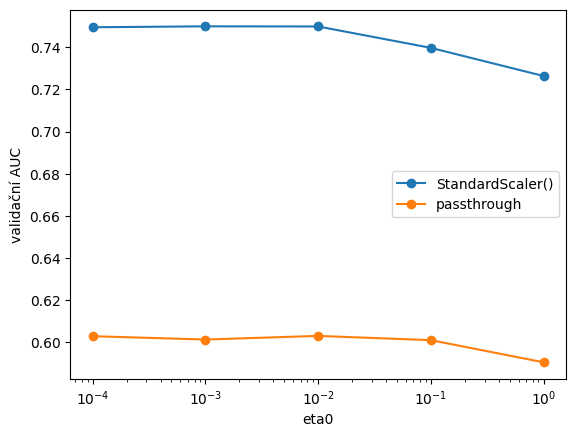

In [11]:
tune_base = Pipeline([("scale", StandardScaler()), ("features", "passthrough"),
                      ("model", SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01, alpha=1e-4, random_state=SEED))])


def validate(params):
    model = clone(tune_base).set_params(**params).fit(X_train, y_train)
    return roc_auc_score(y_val, model.decision_function(X_val))


manual_variants = [
    {},
    {"scale": "passthrough"},
    {"features": PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)},
    {"model__loss": "perceptron"},
    {"model__eta0": 0.0001},
    {"model__eta0": 1},
    {"model__alpha": 0.1},
]
rows = [{"varianta": str(v), "validační AUC": validate(v)} for v in manual_variants]
manual_results = pd.DataFrame(rows).sort_values("validační AUC", ascending=False)
manual_best_params = manual_variants[int(manual_results.index[0])]

combination = {"features": PolynomialFeatures(degree=2, interaction_only=True, include_bias=False), "model__alpha": 0.1}
manual_results.loc[len(rows)] = [str(combination), validate(combination)]
display(manual_results.round(3))
print("manual_best_params:", manual_best_params)

etas = [0.0001, 0.001, 0.01, 0.1, 1]
for scale, name in ((StandardScaler(), "StandardScaler()"), ("passthrough", "passthrough")):
    plt.semilogx(etas, [validate({"scale": scale, "model__eta0": e}) for e in etas], marker="o", label=name)
plt.xlabel("eta0")
plt.ylabel("validační AUC")
plt.legend()
plt.show()  # Zobrazit graf.

**Poznámky k řešení (6.1).** Validační AUC: interakce 0,792 > základ 0,750 ≈ `alpha` 0,1 (0,750) ≈ `eta0` 0,0001 (0,749) > `eta0` 1 (0,726)
> perceptronová ztráta (0,702) > bez škálování (0,603). Kombinace interakce + `alpha` 0,1 dává 0,784, tedy ne víc než samotné interakce.
Bez škálování zůstává AUC kolem 0,60 pro každé `eta0`: žádná rychlost učení nevyrovná měřítka lišící se o tři řády.
Při 40 validačních vadných výliscích jsou rozdíly pod 0,03–0,04 v mezích šumu (srovnejte se směrodatnou odchylkou v 6.2).

### 6.2 Mřížkové hledání s křížovou validací

**Cíl / výstup:** `search` – naučený `GridSearchCV` nad `tune_base`; tabulka `grid_results` s deseti nejlepšími kombinacemi,
jejich průměrným AUC a směrodatnou odchylkou; graf nejlepšího průměrného AUC pro každou ztrátu v závislosti na `eta0`;
`manual_cv` – průměrné AUC vaší ruční volby ze stejné křížové validace.

1. Slovník `param_grid` s pěti parametry z tabulky v kroku 6: 2 · 2 · 2 · 5 · 4 = 160 kombinací.
2. `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.
3. `search = GridSearchCV(tune_base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)` naučený na **vývojových datech**
   `X_dev`, `y_dev`. Testovací data zůstávají stranou. Výpočet trvá několik až desítky sekund.
4. Z `search.cv_results_` sestavte `grid_results`: sloupce `params`, `mean_test_score`, `std_test_score`, deset nejlepších řádků.
   Vypište `search.best_params_` a `search.best_score_`.
5. Graf: pro každou ztrátu nejlepší průměrné AUC (přes ostatní parametry) v závislosti na `eta0`.
6. Ohodnoťte `manual_best_params` z 6.1 stejnou křížovou validací (`cross_val_score` na `X_dev`, `y_dev`) a průměr uložte do `manual_cv`.
7. Ohodnoťte `search.best_params_` s `model__class_weight="balanced"` a bez něj stejnou křížovou validací. Změní se AUC? Proč tak málo?

**Použijte:** `GridSearchCV`, `StratifiedKFold`, `cross_val_score`, `search.best_params_`, `search.best_score_`,
`pd.DataFrame(search.cv_results_)`, `sort_values`, `groupby`.

<details><summary>Nápověda</summary>

Klíče `param_grid` jsou stejné názvy jako v `set_params`; hodnoty jsou seznamy. `cv_results_` obsahuje pro každý parametr sloupec
`param_<název>`, např. `param_model__eta0`. Hodnoty, které jsou objekty (škálovače, kroky příznaků), převeďte před seskupením na text
pomocí `.astype(str)`. Graf lze sestavit jako `tabulka.groupby(["eta0", "loss"])["score"].max().unstack().plot(marker="o", logx=True)`.

</details>

**Zamyslete se:** Odpovídá nejlepší kombinace vaší ruční volbě? Je rozdíl mezi pěti nejlepšími kombinacemi větší než jejich
směrodatná odchylka? Na kterém parametru záleží nejvíc a na kterém skoro vůbec? Odpovídá to edukační části?

### Ukázka: malá mřížka na ilustračních datech

In [12]:
demo_grid = {"model__alpha": [0.0001, 0.05], "model__eta0": [0.005, 0.05]}  # 2 · 2 = 4 kombinace.
demo_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=7)  # Tři části pro malá data.
demo_search = GridSearchCV(demo_base, demo_grid, scoring="roc_auc", cv=demo_cv).fit(demo_X_dev, demo_y_dev)  # Každá kombinace na každé části.
demo_table = pd.DataFrame(demo_search.cv_results_)[["params", "mean_test_score", "std_test_score"]]  # Průměr a rozptyl přes části.
display(demo_table.sort_values("mean_test_score", ascending=False))  # Nejlepší kombinace nahoře.
print(demo_search.best_params_, round(demo_search.best_score_, 3))  # Vítěz a jeho průměrné AUC.
print("průměrné AUC jednoho nastavení:", cross_val_score(demo_base, demo_X_dev, demo_y_dev, scoring="roc_auc", cv=demo_cv).mean().round(3))  # cross_val_score pro jedno nastavení.

,params,mean_test_score,std_test_score
0,"{'model__alpha': 0.0001, 'model__eta0': 0.005}",0.836648,0.004182
2,"{'model__alpha': 0.05, 'model__eta0': 0.005}",0.836174,0.006696
1,"{'model__alpha': 0.0001, 'model__eta0': 0.05}",0.835227,0.004018
3,"{'model__alpha': 0.05, 'model__eta0': 0.05}",0.833807,0.008119


{'model__alpha': 0.0001, 'model__eta0': 0.005} 0.837
průměrné AUC jednoho nastavení: 0.835


**Vlastní kód:**

,params,mean_test_score,std_test_score
111,{'features': PolynomialFeatures(include_bias=F...,0.832,0.039
91,{'features': PolynomialFeatures(include_bias=F...,0.832,0.040
131,{'features': PolynomialFeatures(include_bias=F...,0.832,0.038
87,{'features': PolynomialFeatures(include_bias=F...,0.831,0.039
127,{'features': PolynomialFeatures(include_bias=F...,0.831,0.039
107,{'features': PolynomialFeatures(include_bias=F...,0.831,0.039
147,{'features': PolynomialFeatures(include_bias=F...,0.828,0.039
83,{'features': PolynomialFeatures(include_bias=F...,0.825,0.039
123,{'features': PolynomialFeatures(include_bias=F...,0.825,0.040
103,{'features': PolynomialFeatures(include_bias=F...,0.825,0.039


best_params_: {'features': PolynomialFeatures(include_bias=False, interaction_only=True), 'model__alpha': 0.001, 'model__eta0': 0.01, 'model__loss': 'log_loss', 'scale': StandardScaler()}
best_score_: 0.832


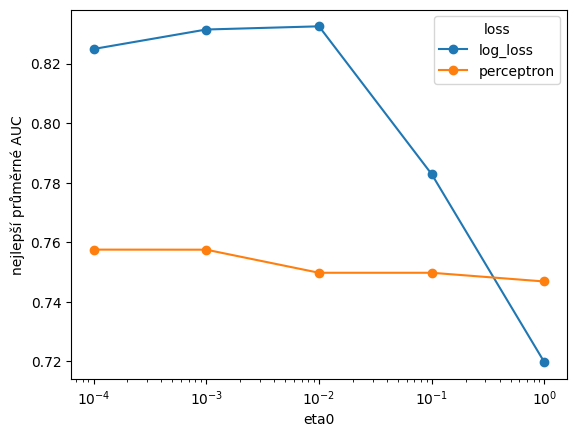

param_scale {'StandardScaler()': 0.832, 'passthrough': 0.694}
param_features {'PolynomialFeatures(include_bias=False, interaction_only=True)': 0.832, 'passthrough': 0.785}
param_model__loss {'log_loss': 0.832, 'perceptron': 0.758}
param_model__eta0 {'0.0001': 0.825, '0.001': 0.831, '0.01': 0.832, '0.1': 0.783, '1.0': 0.747}
param_model__alpha {'0.001': 0.832, '0.01': 0.832, '0.1': 0.828, '1e-05': 0.832}


manual_cv: 0.832
class_weight = None AUC 0.832
class_weight = balanced AUC 0.827


In [13]:
param_grid = {
    "scale": ["passthrough", StandardScaler()],
    "features": ["passthrough", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)],
    "model__loss": ["perceptron", "log_loss"],
    "model__eta0": [0.0001, 0.001, 0.01, 0.1, 1],
    "model__alpha": [0.00001, 0.001, 0.01, 0.1],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
search = GridSearchCV(tune_base, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_dev, y_dev)
results = pd.DataFrame(search.cv_results_)
grid_results = results.sort_values("mean_test_score", ascending=False)[["params", "mean_test_score", "std_test_score"]].head(10)
display(grid_results.round(3))
print("best_params_:", search.best_params_)
print("best_score_:", round(search.best_score_, 3))

table = pd.DataFrame({"eta0": results["param_model__eta0"].astype(float), "loss": results["param_model__loss"].astype(str),
                      "score": results["mean_test_score"]})
table.groupby(["eta0", "loss"])["score"].max().unstack().plot(marker="o", logx=True, ylabel="nejlepší průměrné AUC")
plt.show()  # Zobrazit graf.
for column in ("param_scale", "param_features", "param_model__loss", "param_model__eta0", "param_model__alpha"):
    print(column, results.groupby(results[column].astype(str))["mean_test_score"].max().round(3).to_dict())

manual_cv = cross_val_score(clone(tune_base).set_params(**manual_best_params), X_dev, y_dev, scoring="roc_auc", cv=cv).mean()
print("manual_cv:", round(manual_cv, 3))
for weight in (None, "balanced"):
    weighted = clone(tune_base).set_params(**search.best_params_, model__class_weight=weight)
    print("class_weight =", weight, "AUC", round(cross_val_score(weighted, X_dev, y_dev, scoring="roc_auc", cv=cv).mean(), 3))

**Poznámky k řešení (6.2).** Nejlepší: `StandardScaler()`, interakce, `log_loss`, `eta0` 0,01, `alpha` 0,001; průměrné AUC 0,832 ± 0,039.
Deset nejlepších kombinací se liší o méně než 0,01 – mnohem méně, než je směrodatná odchylka; jsou prakticky rovnocenné.
Nejlepší skóre pro každou hodnotu ukazuje, na čem záleží: škálování (0,832 vs. 0,694), ztráta (0,832 vs. 0,758), interakce (0,832 vs. 0,785),
`eta0` (0,832 při 0,01 vs. 0,783 při 0,1 a 0,747 při 1); na `alpha` téměř vůbec (1500 vzorků, málo příznaků). `manual_cv` = 0,832: ruční volba
(interakce) je stejně dobrá jako optimum mřížky. `class_weight="balanced"` změní průměrné AUC jen nepatrně (0,832 → 0,827): převážení hlavně posune skóre,
pořadí mění málo.

### 6.3 Rozhodovací práh podle ceny chyb

**Cíl / výstup:** `chosen_params` – parametry výsledného modelu; `dev_proba` – pravděpodobnosti vady pro všechny vývojové
výlisky z modelů, které je při učení neviděly; tabulka `threshold_costs` s celkovou cenou pro prahy 0,01, 0,02, …, 0,99; nejlevnější práh
`chosen_threshold`; graf ceny (a přesnosti a úplnosti) v závislosti na prahu.

1. Práh potřebuje **pravděpodobnosti**, výsledný model proto musí být logistický neuron. `chosen_params` = `search.best_params_`,
   pokud je jeho `model__loss` rovno `"log_loss"`; jinak vezměte nejlepší řádek s `"log_loss"` ze všech kombinací, `pd.DataFrame(search.cv_results_)`.
2. `dev_proba = cross_val_predict(clone(tune_base).set_params(**chosen_params), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]`.
   Každý výlisek dostane pravděpodobnost od modelu, který ho při učení neviděl.
3. Pro každý práh t spočtěte předpovědi `dev_proba >= t` a jejich celkovou cenu pomocí `evaluate`. Tabulku uložte do `threshold_costs`
   a nejlevnější práh do `chosen_threshold`.
4. Porovnejte `chosen_threshold` s teoretickou hodnotou C_FP / (C_FP + C_FN) = 1/11 ≈ 0,091 a s cenou při 0,5.
5. Nakreslete cenu v závislosti na prahu; do druhého grafu přesnost a úplnost v závislosti na prahu.
6. Zopakujte kroky 2 a 3 s `model__class_weight="balanced"` přidaným do kopie `chosen_params` (samotné `chosen_params` neměňte).
   Kde je nejlevnější práh teď a proč? Je minimální cena nižší?

**Použijte:** `cross_val_predict`, cyklus `for` přes `np.round(np.arange(0.01, 1.0, 0.01), 2)`, `evaluate`, `pd.DataFrame`, `idxmin`, `plt.plot`.

<details><summary>Nápověda</summary>

Nejlepší kombinace s danou ztrátou: `tabulka = pd.DataFrame(search.cv_results_)`, potom `tabulka[tabulka["param_model__loss"] == "log_loss"].sort_values("mean_test_score").iloc[-1]["params"]`.
Pravděpodobnosti mimo učení pocházejí z pěti modelů, každý naučený na čtyřech pětinách `X_dev`; práh se proto volí bez testovacích dat
a bez optimismu předpovědí na trénovacích datech. Sbírejte řádky `{"threshold": t, **evaluate(y_dev, dev_proba >= t)}` a z nich sestavte tabulku.

</details>

**Zamyslete se:** Jak daleko je nejlevnější práh od 0,5? Kolik vad při něm přehlédnete a kolik dobrých výlisků pošlete na kontrolu?
Proč zde teoretická hodnota 1/11 platí jen přibližně?

### Ukázka: cena pro několik prahů

In [14]:
demo_dev_proba = cross_val_predict(demo_base, demo_X_dev, demo_y_dev, cv=demo_cv, method="predict_proba")[:, 1]  # Pravděpodobnosti z modelů, které vzorek neviděly.
demo_rows = [{"threshold": t, **evaluate(demo_y_dev, demo_dev_proba >= t)} for t in (0.05, 0.1, 0.3, 0.5)]  # Jeden řádek na práh.
demo_costs = pd.DataFrame(demo_rows).set_index("threshold")  # Prahy jako index řádků.
display(demo_costs.round(3))  # Tabulka.
print("nejlevnější z těchto prahů:", demo_costs["cena"].idxmin())  # Řádek s nejnižší cenou.

,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
threshold,,,,,,,,,,
0.05,78,114,3,30,0.480,0.208,0.909,0.339,0.658,144
0.10,123,69,6,27,0.667,0.281,0.818,0.419,0.729,129
0.30,172,20,15,18,0.844,0.474,0.545,0.507,0.721,170
0.50,187,5,25,8,0.867,0.615,0.242,0.348,0.608,255


nejlevnější z těchto prahů: 0.1


**Vlastní kód:**

chosen_params: {'features': PolynomialFeatures(include_bias=False, interaction_only=True), 'model__alpha': 0.001, 'model__eta0': 0.01, 'model__loss': 'log_loss', 'scale': StandardScaler()}


chosen_threshold = 0.07, cena 689; teorie 0.091; cena při 0,5 1225; vždy dobrý 1610


,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
threshold,,,,,,,,,,
0.07,880,459,23,138,0.679,0.231,0.857,0.364,0.757,689
0.09,963,376,37,124,0.725,0.248,0.770,0.375,0.745,746
0.20,1202,137,71,90,0.861,0.396,0.559,0.464,0.728,847
0.50,1314,25,120,41,0.903,0.621,0.255,0.361,0.618,1225


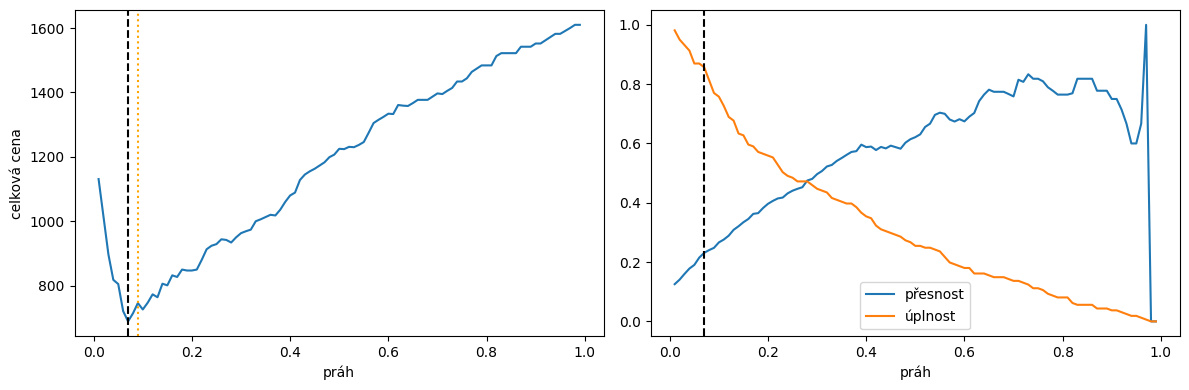

class_weight='balanced': nejlevnější práh 0.46, cena 694


In [15]:
if search.best_params_["model__loss"] == "log_loss":
    chosen_params = search.best_params_
else:
    chosen_params = results[results["param_model__loss"] == "log_loss"].sort_values("mean_test_score").iloc[-1]["params"]
print("chosen_params:", chosen_params)

dev_proba = cross_val_predict(clone(tune_base).set_params(**chosen_params), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
threshold_costs = pd.DataFrame([{"threshold": t, **evaluate(y_dev, dev_proba >= t)} for t in thresholds]).set_index("threshold")
chosen_threshold = float(threshold_costs["cena"].idxmin())
print(f"chosen_threshold = {chosen_threshold}, cena {threshold_costs.loc[chosen_threshold, 'cena']}; "
      f"teorie {C_FP / (C_FP + C_FN):.3f}; cena při 0,5 {threshold_costs.loc[0.5, 'cena']}; "
      f"vždy dobrý {C_FN * int(y_dev.sum())}")
display(threshold_costs.loc[[chosen_threshold, 0.09, 0.2, 0.5]].round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(thresholds, threshold_costs["cena"])
axs[0].axvline(chosen_threshold, color="black", ls="--")
axs[0].axvline(C_FP / (C_FP + C_FN), color="orange", ls=":")
axs[0].set(xlabel="práh", ylabel="celková cena")
axs[1].plot(thresholds, threshold_costs["přesnost"], label="přesnost")
axs[1].plot(thresholds, threshold_costs["úplnost"], label="úplnost")
axs[1].axvline(chosen_threshold, color="black", ls="--")
axs[1].set(xlabel="práh")
axs[1].legend()
plt.tight_layout()  # Popisky se nepřekrývají.
plt.show()  # Zobrazit graf.

balanced = {**chosen_params, "model__class_weight": "balanced"}
balanced_proba = cross_val_predict(clone(tune_base).set_params(**balanced), X_dev, y_dev, cv=cv, method="predict_proba")[:, 1]
balanced_costs = pd.Series({t: evaluate(y_dev, balanced_proba >= t)["cena"] for t in thresholds})
print(f"class_weight='balanced': nejlevnější práh {balanced_costs.idxmin()}, cena {balanced_costs.min()}")

**Poznámky k řešení (6.3).** Nejlevnější práh 0,07 s cenou 689 na 1500 vývojových výliscích; teoretická hodnota 1/11 ≈ 0,091 dává 746,
práh 0,5 dává 1225 a „vždy dobrý“ 1610. Při 0,07: úplnost 0,86, přesnost 0,23 – 23 přehlédnutých vad a 459 dobrých výlisků poslaných na kontrolu.
Teorie předpokládá přesně kalibrované pravděpodobnosti; tyto pocházejí z regularizovaného modelu učeného stochastickým sestupem na 1500 výliscích
a křivka ceny je u minima plochá a zašuměná, proto se oba prahy mírně liší. S `class_weight="balanced"` se nejlevnější
práh posune na 0,46 při téměř stejné ceně (694): převážení nafoukne pravděpodobnosti vad, vzorec pro ně přestane platit
a práh to vyrovná.

## 7. Zmrazení volby a závěrečný test

**Cíl / výstup:** `final_pipeline` – `tune_base` s `chosen_params`, naučený na všech vývojových datech;
testovací pravděpodobnosti `test_proba`; testovací rozhodnutí `test_pred` při `chosen_threshold`; tabulka `final_table`, která na testu srovnává
model při `chosen_threshold`, týž model při 0,5 a „vždy dobrý“; matice záměn.

Volba je zmrazená: parametry z 6.2, práh z 6.3. Vytvořte `final_pipeline` jako `clone(tune_base)` s `chosen_params`,
naučte ho na `X_dev`, `y_dev` (1500 výlisků) a teprve pak jednou předpovězte `X_test`.

**Použijte:** `clone`, `.set_params(**...)`, `.fit`, `.predict_proba`, `evaluate`, `ConfusionMatrixDisplay.from_predictions`.

<details><summary>Nápověda</summary>

Pro „vždy dobrý“ použijte `np.zeros(len(y_test), dtype=int)`. Testovací cíle slouží jen k vyhodnocení.

</details>

**Po zobrazení testovacích výsledků už následuje jen interpretace.** Změna prahu nebo parametrů podle testovacích výsledků
by z testovacích dat udělala další validační data.

**Zamyslete se:** Kolik vad model na testu přehlédl a kolik dobrých výlisků poslal na kontrolu?
Kolik ušetří zvolený práh oproti 0,5 a oproti žádnému modelu? Je testovací AUC blízko `search.best_score_`?

### Ukázka: nové naučení zmrazené volby a jeden test

In [16]:
demo_final = clone(demo_base).set_params(**demo_search.best_params_).fit(demo_X_dev, demo_y_dev)  # Zmrazené nastavení, všechna vývojová data.
demo_test_proba = demo_final.predict_proba(demo_X_test)[:, 1]  # Jediná předpověď testovacích dat.
display(pd.DataFrame([evaluate(demo_y_test, demo_test_proba >= 0.1)], index=["práh 0,1"]).round(3))  # Vyhodnoceno jednou.

,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
"práh 0,1",36,28,2,9,0.6,0.243,0.818,0.375,0.69,48


**Vlastní kód:**

,TN,FP,FN,TP,správnost,přesnost,úplnost,F1,vyvážená správnost,cena
práh 0.07,293,154,6,47,0.680,0.234,0.887,0.370,0.771,214
"práh 0,5",439,8,44,9,0.896,0.529,0.170,0.257,0.576,448
vždy dobrý,447,0,53,0,0.894,0.000,0.000,0.000,0.500,530


testovací AUC 0.824, křížová validace 0.832


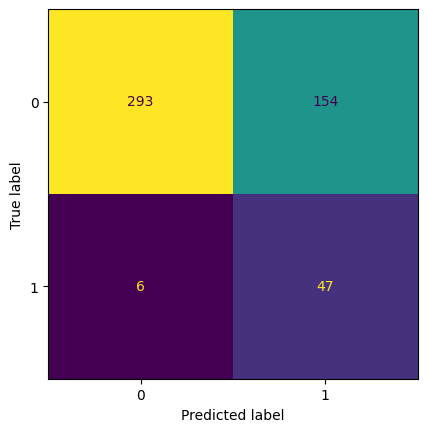

In [17]:
final_pipeline = clone(tune_base).set_params(**chosen_params).fit(X_dev, y_dev)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= chosen_threshold).astype(int)
final_table = pd.DataFrame(
    [evaluate(y_test, test_pred), evaluate(y_test, (test_proba >= 0.5).astype(int)), evaluate(y_test, np.zeros(len(y_test), dtype=int))],
    index=[f"práh {chosen_threshold}", "práh 0,5", "vždy dobrý"])
display(final_table.round(3))
print(f"testovací AUC {roc_auc_score(y_test, test_proba):.3f}, křížová validace {search.best_score_:.3f}")
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, colorbar=False)
plt.show()  # Zobrazit graf.

**Poznámky k řešení (krok 7).** Test (500 výlisků, 53 vadných): práh 0,07 – FN 6, FP 154, úplnost 0,89, přesnost 0,23, cena 214;
práh 0,5 – FN 44, cena 448; „vždy dobrý“ – cena 530. Zvolený práh ušetří asi 60 % ceny oproti stavu bez modelu.
Testovací AUC 0,824 je blízko odhadu z křížové validace 0,832.